<a href="https://colab.research.google.com/github/giridharggn-beep/sales-prediction-model/blob/main/project2_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Predictive Sales Model***

### Introduction

**This project aims to build a machine learning model to predict sales using historical sales data.**

# Sales Prediction Using Machine Learning

## Project Objective

The objective of this project is to analyze sales data and develop a machine learning model to predict sales based on the available features.

In [1]:
import pandas as pd

df = pd.read_csv('SampleSuperstore1.csv')

df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [2]:
X = df[['Quantity', 'Discount', 'Category', 'Sub-Category', 'Region']]
y = df['Sales']

print(X.head())
print(y.head())

   Quantity  Discount         Category Sub-Category Region
0         2      0.00        Furniture    Bookcases  South
1         3      0.00        Furniture       Chairs  South
2         2      0.00  Office Supplies       Labels   West
3         5      0.45        Furniture       Tables  South
4         2      0.20  Office Supplies      Storage  South
0    261.9600
1    731.9400
2     14.6200
3    957.5775
4     22.3680
Name: Sales, dtype: float64


In [3]:
X_encoded = pd.get_dummies(X, columns=['Category', 'Sub-Category', 'Region'])

X_encoded.head()

,Quantity,Discount,Category_Furniture,Category_Office Supplies,Category_Technology,Sub-Category_Accessories,Sub-Category_Appliances,Sub-Category_Art,Sub-Category_Binders,Sub-Category_Bookcases,...,Sub-Category_Machines,Sub-Category_Paper,Sub-Category_Phones,Sub-Category_Storage,Sub-Category_Supplies,Sub-Category_Tables,Region_Central,Region_East,Region_South,Region_West
0,2,0.00,True,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,True,False
1,3,0.00,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,2,0.00,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,5,0.45,True,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
4,2,0.20,False,True,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,True,False


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (7995, 26)
Testing data: (1999, 26)


In [5]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [6]:
y_pred = model.predict(X_test)

print(y_pred[:5])

[237.58929768  64.18247914  74.885225   449.69902597 590.02489227]


In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R²:", rf_r2)

Random Forest Results
MAE: 200.71483463115757
RMSE: 674.612156425343
R²: 0.22955441576206903


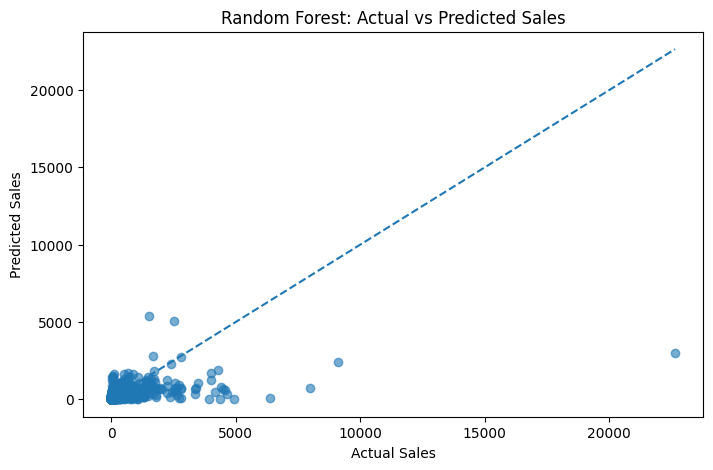

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_pred, alpha=0.6)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Random Forest: Actual vs Predicted Sales")

plt.show()

In [9]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)


MAE: 226.33273970193892
RMSE: 693.3279879275931
R²: 0.18621232412059896


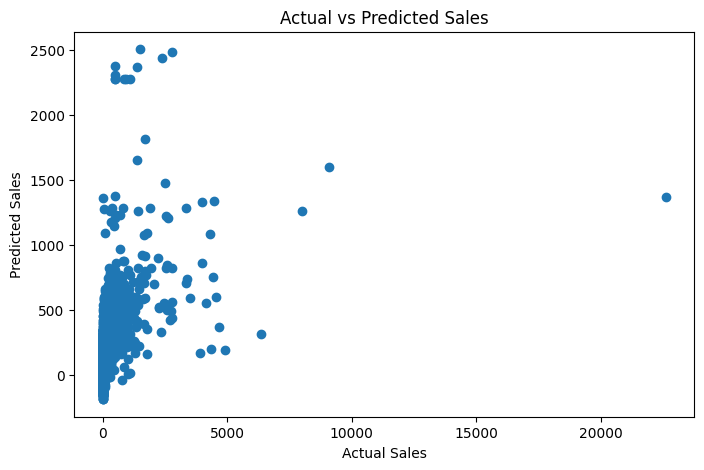

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

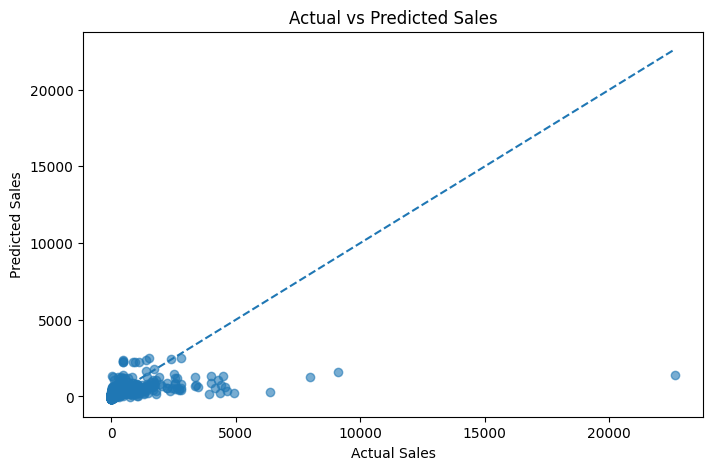

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()

# Key Insights

- Two machine learning models were evaluated: Linear Regression and Random Forest Regression.
- Random Forest performed better than Linear Regression based on all three evaluation metrics.
- Random Forest achieved an MAE of 200.71, meaning the average prediction error is about 201 sales units.
- The RMSE of Random Forest is 674.61, indicating that some predictions have relatively large errors.
- The R² score is 0.2296, meaning the model explains approximately 22.96% of the variation in sales.
- The Actual vs Predicted graph shows that the model performs better for lower and moderate sales values but tends to underestimate some very high sales values.
- Further improvement could be achieved by using additional relevant features, handling outliers, and tuning the model parameters.

# **Conclusion**

**In this project, machine learning models were developed to predict sales using historical sales data. Linear Regression and Random Forest Regression were evaluated using MAE, RMSE, and R² metrics. The Random Forest model performed better, achieving an MAE of 200.71, RMSE of 674.61, and R² of 0.2296. Although the model provides useful sales predictions, its performance is limited for some high-sales observations. The model can be further improved through better feature selection, outlier handling, and hyperparameter tuning.**